# 2026-10-20: Close-to-peak and post-peak SFR excess, without an inclination cut

Adapted from cells 1-13 and 34 (one-based notebook positions) of
`20261015_check_NGC4654_rSFMS_excess_Fourier_local_enhancement.ipynb`.
The source is preserved. This notebook contains the global SFR-excess analysis
only, with no Fourier fit, radial exclusion, or directional/sector selection.

All catalogue close-to-peak and post-peak products are requested regardless of
inclination. The pre-peak reference excludes galaxies with inclination >80 deg
(retaining inclination <=80 deg). Only those available pre-peak products define
the equal-product reference and common width W.
NGC4567_8 remains one combined reference product.

The inventory explicitly lists missing products. A missing product is not a
non-detection; a galaxy with zero selected SF spaxels has undefined fractions.
Cell 14 adapts source cell 34 to one two-panel context figure per available
comparison galaxy, with stage-specific tail comparisons and common count bins
and colour scale. Galaxy colours follow the project colour guide; the source's
NGC4654 green override is retained.

These are descriptive selected-spaxel fractions, not independent-region
statistics or causal evidence of enhancement. E is in units of W, not sigma
significance. Including edge-on galaxies does not remove projection effects.

**Selection update:** close-to-peak and post-peak SF spaxels additionally require
finite stellar-continuum `SNR_POSTFIT > 25` from each galaxy's SFH map. This strict
cut applies before all comparison plots, excess maps, counts, and fraction
denominators. Pre-peak products have the inclination <=80 deg selection above
and no additional SNR_POSTFIT cut; their reference line and width are refitted.
The QC table reports SF counts before and after this additional cut.


In [2]:
from pathlib import Path
import hashlib, platform
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.wcs import WCS
from IPython.display import display, Markdown

PROJECT_ROOT = Path('/Users/Igniz/Desktop/ICRAR/further')
DATA_ROOT = PROJECT_ROOT / 'v3tk_v7.6.8'
CATALOG_PATH = PROJECT_ROOT / 'mauve_master_wiki_newclass.fits'
GEOMETRY_PATH = PROJECT_ROOT / 'MAUVE_effective_radii.csv'
GALAXY_COLOR_PATH = PROJECT_ROOT / '20260530_MAUVE_galaxy_colors.md'
SFH_SNR_POSTFIT_HDU = 'SNR_POSTFIT'
SFH_SNR_POSTFIT_MIN = 25.0
PRE_PEAK_INCLINATION_MAX = 80.0  # inclusive; exclude only >80 deg
SFH_FILE_PATTERN = '{galid}_sfh_maps.fits'
EW_HA_MIN = 6.0
HALPHA_SIGMA_MAX = 45.0
WCS_TOLERANCE_ARCSEC = 0.05
MASS_HDU = 'LOGMASS_SURFACE_DENSITY'
BIN_HDU_MASS = 'BINID'
BIN_HDU_GAS = 'BIN_ID'
SFR_HDU_PRIMARY = 'LOGSFR_SURFACE_DENSITY_HII'
EW_HDU = 'PROXY_EWHA'
HALPHA_SIGMA_OBS_HDU = 'HA6562_SIGMA'
HALPHA_SIGMA_CORR_HDU = 'HA6562_SIGMA_CORR'
MASK_TABLE_HDU = 'MASKFILE'
MASK_COLUMN = 'MASK'
MASS_FILE_PATTERN = '{galid}_spatial_binning_maps_further.fits'
SFR_FILE_PATTERNS = ('{galid}_gas_bin_maps_further.fits', '{galid}_gas_BIN_maps_further.fits')
EW_FILE_PATTERNS = ('{galid}_proxy_EW_maps_further.fits', '{galid}_proxy_EW_maps.fits')
MASK_FILE_PATTERN = '{galid}_mask.fits'
MAP_LIMIT = 4.0  # display saturation only; fractions/histograms use all values
mpl.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.grid': False})
EXCESS_THRESHOLDS = (1, 1.5, 2, 2.5, 3, 3.5, 4)


## 1. Live sample, masks and map provenance


Inherited SF selection: finite HII log SFR and stellar density, unmasked usable
footprint, proxy EW(Halpha)>6 Angstrom, and 0<intrinsic Halpha dispersion<45 km/s.
For close-to-peak and post-peak only, additionally require finite stellar
SNR_POSTFIT > 25 from the SFH map, with no inclination cut. Pre-peak reference
products require inclination <=80 deg and have no additional SNR_POSTFIT cut.
Intrinsic dispersion is sqrt(observed dispersion squared minus correction
squared). No additional SFR-error cut is imposed on fitting or excess maps.

The current products have no dedicated SFR-error HDU. Since SFR is proportional
to corrected Halpha flux, derive the first-order log SFR error in dex as
`HA6562_FLUX_ERR_CORR / (HA6562_FLUX_CORR * ln(10))`. Use the existing corrected
flux uncertainty, which includes the pipeline's dust-error treatment; do not
add that term again. Fixed conversion/area factors cancel in the relative error.
Distance, inclination, calibration systematics, stellar-density errors, and
fitted-line uncertainty are not included. Invalid/negative errors are excluded
only from width estimation and their counts are displayed.

In [4]:
def normalise_stage_label(value) -> str:
    mapping = {
        1: "pre-peak", 1.0: "pre-peak", "1": "pre-peak",
        2: "close-to-peak", 2.0: "close-to-peak", "2": "close-to-peak",
        3: "post-peak", 3.0: "post-peak", "3": "post-peak",
        "prepeak": "pre-peak", "pre-peak": "pre-peak",
        "close-to-peak": "close-to-peak", "closetopeak": "close-to-peak",
        "near-peak": "close-to-peak", "postpeak": "post-peak",
        "post-peak": "post-peak",
    }
    key = value if isinstance(value, (int, float)) else str(value).strip().lower().replace(" ", "")
    if key not in mapping:
        raise ValueError(f"Unrecognised RPS/infall stage label: {value!r}")
    return mapping[key]

def first_existing(paths):
    for path in paths:
        if path.exists():
            return path
    return None

def load_fits_map(path: Path, hdu_name: str, *, return_header: bool = False):
    if not path.exists():
        raise FileNotFoundError(path)
    with fits.open(path, memmap=True) as hdul:
        names = {h.name.upper() for h in hdul}
        if hdu_name.upper() not in names:
            raise KeyError(f"{path}: missing HDU {hdu_name}; available={sorted(names)}")
        hdu = hdul[hdu_name]
        data = np.asarray(hdu.data, dtype=float).copy()
        header = hdu.header.copy()
    return (data, header) if return_header else data

def load_ngist_mask(path: Path, shape):
    if not path.exists():
        raise FileNotFoundError(path)
    with fits.open(path, memmap=True) as hdul:
        if MASK_TABLE_HDU not in hdul:
            raise KeyError(f"{path}: missing table HDU {MASK_TABLE_HDU}")
        table = hdul[MASK_TABLE_HDU].data
        if MASK_COLUMN not in table.names:
            raise KeyError(f"{path}: missing mask column {MASK_COLUMN}; available={table.names}")
        flat = np.asarray(table[MASK_COLUMN], dtype=int)
    if flat.size != int(np.prod(shape)):
        raise ValueError(f"{path}: mask length {flat.size} cannot reshape to {shape}")
    return flat.reshape(shape)

def celestial_wcs_separation_arcsec(header_a, header_b, shape):
    wa = WCS(header_a).celestial
    wb = WCS(header_b).celestial
    if not wa.has_celestial or not wb.has_celestial:
        return np.inf
    ny, nx = shape
    x = np.array([0, nx - 1, 0, nx - 1, (nx - 1) / 2])
    y = np.array([0, 0, ny - 1, ny - 1, (ny - 1) / 2])
    raa, deca = wa.pixel_to_world_values(x, y)
    rab, decb = wb.pixel_to_world_values(x, y)
    cosd = np.cos(np.deg2rad((deca + decb) / 2))
    return float(np.nanmax(np.hypot((raa - rab) * cosd, deca - decb)) * 3600.0)

def tangent_offsets_arcsec(ra_deg, dec_deg, ra0_deg, dec0_deg):
    ra, dec = np.deg2rad(ra_deg), np.deg2rad(dec_deg)
    ra0, dec0 = np.deg2rad(float(ra0_deg)), np.deg2rad(float(dec0_deg))
    dra = (ra - ra0 + np.pi) % (2 * np.pi) - np.pi
    cosc = np.sin(dec0) * np.sin(dec) + np.cos(dec0) * np.cos(dec) * np.cos(dra)
    with np.errstate(divide="ignore", invalid="ignore"):
        east = np.cos(dec) * np.sin(dra) / cosc
        north = (np.cos(dec0) * np.sin(dec) - np.sin(dec0) * np.cos(dec) * np.cos(dra)) / cosc
    return east * 206264.806247, north * 206264.806247

def calculate_deprojected_radius(shape, header, component_rows: pd.DataFrame):
    """Return min elliptical R/Re over physical components (union geometry for NGC4567_8)."""
    wcs = WCS(header).celestial
    if not wcs.has_celestial:
        raise ValueError("No celestial WCS available for radius calculation")
    yy, xx = np.indices(shape, dtype=float)
    ra, dec = wcs.pixel_to_world_values(xx, yy)
    radius = np.full(shape, np.inf, dtype=float)
    for _, row in component_rows.iterrows():
        east, north = tangent_offsets_arcsec(ra, dec, row.center_ra_deg, row.center_dec_deg)
        pa = np.deg2rad(float(row.pa_deg_east_of_north))
        major = east * np.sin(pa) + north * np.cos(pa)
        minor = east * np.cos(pa) - north * np.sin(pa)
        r = np.sqrt((major / float(row.a_re_arcsec)) ** 2 + (minor / float(row.b_re_arcsec)) ** 2)
        radius = np.minimum(radius, r)
    radius[~np.isfinite(radius)] = np.nan
    return radius

def make_valid_disc_mask(log_sigma_star, bin_id, ngist_mask, radius_re):
    return (
        np.isfinite(log_sigma_star)
        & np.isfinite(bin_id)
        & (ngist_mask == 0)
        & np.isfinite(radius_re)
    )

def intrinsic_sigma_from_maps(sigma_obs, sigma_corr):
    sigma_obs = np.asarray(sigma_obs, dtype=float)
    sigma_corr = np.asarray(sigma_corr, dtype=float)
    if sigma_obs.shape != sigma_corr.shape:
        raise ValueError(
            f"Observed/correction Halpha sigma shape mismatch: {sigma_obs.shape} vs {sigma_corr.shape}"
        )
    sigma2_intrinsic = sigma_obs**2 - sigma_corr**2
    sigma_intrinsic = np.full(sigma_obs.shape, np.nan, dtype=float)
    valid = np.isfinite(sigma2_intrinsic) & (sigma2_intrinsic > 0)
    sigma_intrinsic[valid] = np.sqrt(sigma2_intrinsic[valid])
    return sigma_intrinsic

def make_sf_mask(valid_disc_mask, log_sigma_sfr, ew_ha, halpha_sigma_intrinsic):
    """Project SF definition: HII/SF map + EW(Halpha)>6 A + intrinsic sigma<45 km/s."""
    return (
        valid_disc_mask
        & np.isfinite(log_sigma_sfr)
        & np.isfinite(ew_ha)
        & (ew_ha > EW_HA_MIN)
        & np.isfinite(halpha_sigma_intrinsic)
        & (halpha_sigma_intrinsic < HALPHA_SIGMA_MAX)
    )

def load_galaxy_maps(row, geometry, sfr_hdu=SFR_HDU_PRIMARY):
    mass, mass_header = load_fits_map(row.mass_path, MASS_HDU, return_header=True)
    mass_bin = load_fits_map(row.mass_path, BIN_HDU_MASS)
    gas_bin, gas_header = load_fits_map(row.sfr_path, BIN_HDU_GAS, return_header=True)
    sfr = load_fits_map(row.sfr_path, sfr_hdu)
    ew_ha = load_fits_map(row.ew_path, EW_HDU)
    halpha_sigma_obs = load_fits_map(row.sfr_path, HALPHA_SIGMA_OBS_HDU)
    halpha_sigma_corr = load_fits_map(row.sfr_path, HALPHA_SIGMA_CORR_HDU)
    shapes = {
        mass.shape, mass_bin.shape, gas_bin.shape, sfr.shape, ew_ha.shape,
        halpha_sigma_obs.shape, halpha_sigma_corr.shape,
    }
    if len(shapes) != 1:
        raise ValueError(f"{row.GALID}: map shape mismatch {sorted(shapes)}")
    wcs_sep = celestial_wcs_separation_arcsec(mass_header, gas_header, mass.shape)
    if not np.isfinite(wcs_sep) or wcs_sep > WCS_TOLERANCE_ARCSEC:
        raise ValueError(f"{row.GALID}: mass/gas WCS mismatch {wcs_sep:.4f} arcsec")
    ngist_mask = load_ngist_mask(row.mask_path, mass.shape)
    components = geometry.loc[geometry.notebook_product_id.eq(row.GALID)].copy()
    if components.empty:
        raise KeyError(f"{row.GALID}: no geometry rows")
    radius_re = calculate_deprojected_radius(mass.shape, mass_header, components)
    halpha_sigma_intrinsic = intrinsic_sigma_from_maps(halpha_sigma_obs, halpha_sigma_corr)
    valid = make_valid_disc_mask(mass, gas_bin, ngist_mask, radius_re)
    classification = valid & np.isfinite(sfr)
    sf = make_sf_mask(valid, sfr, ew_ha, halpha_sigma_intrinsic)
    return {
        "log_sigma_star": mass,
        "log_sigma_sfr": sfr,
        "ew_ha": ew_ha,
        "halpha_sigma_intrinsic": halpha_sigma_intrinsic,
        "mass_bin_id": mass_bin,
        "gas_bin_id": gas_bin,
        "ngist_mask": ngist_mask,
        "radius_re": radius_re,
        "valid_disc_mask": valid,
        "classification_mask": classification,
        "sf_mask": sf,
        "wcs_separation_arcsec": wcs_sep,
    }

def load_galaxy_colors(path):
    """Load identity colours from the project Markdown guide."""
    colors = {}
    for line in path.read_text().splitlines():
        if not line.startswith('|'):
            continue
        fields = [field.strip() for field in line.split('|')[1:-1]]
        if len(fields) == 4 and fields[1].startswith(('NGC', 'IC')):
            color = fields[3].strip('`')
            if color.startswith('#'):
                colors[fields[1]] = color
    return colors

def read_master_catalogue(path):
    with fits.open(path) as hdul:
        table = hdul[1].data
        required = {"Galaxy", "logMstar", "class"}
        missing = required - set(table.names)
        if missing:
            raise KeyError(f"{path}: missing catalogue columns {sorted(missing)}")
        frame = pd.DataFrame({
            "galaxy": [str(v).strip() for v in table["Galaxy"]],
            "logMstar": np.asarray(table["logMstar"], dtype=float),
            "stage_code": np.asarray(table["class"], dtype=float),
        })
    frame["stage"] = frame.stage_code.map(normalise_stage_label)
    return frame

def discover_products(data_root):
    rows = []
    for folder in sorted(p for p in data_root.iterdir() if p.is_dir() and not p.name.endswith("_logs")):
        galid = folder.name
        mass_base = folder / MASS_FILE_PATTERN.format(galid=galid)
        mass = first_existing([mass_base, Path(str(mass_base)+'.gz')]) or mass_base
        sfr_paths = [folder / p.format(galid=galid) for p in SFR_FILE_PATTERNS]
        sfr = first_existing(sfr_paths + [Path(str(p)+'.gz') for p in sfr_paths])
        ew_paths = [folder / p.format(galid=galid) for p in EW_FILE_PATTERNS]
        ew = first_existing(ew_paths + [Path(str(p)+'.gz') for p in ew_paths])
        mask_base = folder / MASK_FILE_PATTERN.format(galid=galid)
        mask = first_existing([mask_base, Path(str(mask_base)+'.gz')]) or mask_base
        sfh_base = folder / SFH_FILE_PATTERN.format(galid=galid)
        sfh = first_existing([sfh_base, Path(str(sfh_base)+'.gz')])
        rows.append({"sfh_path": sfh, "GALID": galid, "mass_path": mass, "sfr_path": sfr, "ew_path": ew, "mask_path": mask})
    return pd.DataFrame(rows)



In [5]:
SOURCE_SHA256_AT_CREATION = {'20261015_check_NGC4654_rSFMS_excess_Fourier_local_enhancement.ipynb': '53cff7fedc2ed3a7f7d8b8e758bf5dc47c9c805b856abb21108c6fc2cd79810b'}
print('Source notebook SHA256:', SOURCE_SHA256_AT_CREATION)
for p in (CATALOG_PATH, GEOMETRY_PATH, GALAXY_COLOR_PATH):
    print(p.name, hashlib.sha256(p.read_bytes()).hexdigest())
master = read_master_catalogue(CATALOG_PATH)
geometry = pd.read_csv(GEOMETRY_PATH).merge(master[['galaxy', 'logMstar', 'stage']],
    on='galaxy', how='left', validate='one_to_one')
assert geometry.stage.notna().all()
assert geometry.stage.eq(geometry.mauve_infall_stage.map(normalise_stage_label)).all()
assert set(master.galaxy) <= set(geometry.galaxy), 'Catalogue galaxies missing geometry'
meta = []
for galid, group in geometry.groupby('notebook_product_id', sort=True):
    if group.stage.nunique() != 1:
        raise ValueError(f'{galid}: mixed stages within combined product')
    meta.append(dict(GALID=galid, stage=group.stage.iloc[0],
        n_components=len(group), inclination=group.inclination_deg.max()))
inventory = pd.DataFrame(meta).merge(discover_products(DATA_ROOT), on='GALID',
    how='left', validate='one_to_one')
inventory['requested'] = inventory.stage.isin(['pre-peak', 'close-to-peak', 'post-peak'])
def missing_inputs(row):
    return ', '.join(label for label in (('mass', 'sfr', 'ew', 'mask', 'sfh')
            if row.stage in ('close-to-peak', 'post-peak') else ('mass', 'sfr', 'ew', 'mask'))
        if not isinstance(getattr(row, label + '_path'), Path)
        or not getattr(row, label + '_path').exists())
inventory['missing_inputs'] = [missing_inputs(row) for row in inventory.itertuples(index=False)]
inventory['inclination_ok'] = (~inventory.stage.eq('pre-peak')
    | inventory.inclination.le(PRE_PEAK_INCLINATION_MAX))
inventory['included'] = inventory.requested & inventory.inclination_ok & inventory.missing_inputs.eq('')
inventory['selection_reason'] = np.select(
    [~inventory.inclination_ok, ~inventory.missing_inputs.eq(''), inventory.stage.eq('pre-peak')],
    ['excluded: pre-peak inclination >80 deg / missing', 'unavailable: ' + inventory.missing_inputs,
     'selected (pre-peak inclination <=80 deg)'],
    default='selected (no inclination cut; SNR_POSTFIT >25)')
display(inventory[['GALID','stage','n_components','inclination','selection_reason']])
selected = inventory.loc[inventory.included].copy()
pre_ids = sorted(selected.loc[selected.stage.eq('pre-peak'), 'GALID'])
close_ids = sorted(selected.loc[selected.stage.eq('close-to-peak'), 'GALID'])
post_ids = sorted(selected.loc[selected.stage.eq('post-peak'), 'GALID'])
comparison_ids = close_ids + post_ids
for stage, ids in [('pre-peak', pre_ids), ('close-to-peak', close_ids), ('post-peak', post_ids)]:
    print(stage, 'available:', len(ids), ids)
    print(stage, 'unavailable:', inventory.loc[inventory.stage.eq(stage) & ~inventory.missing_inputs.eq(''), 'GALID'].tolist())
assert pre_ids and close_ids and post_ids
print('Excluded pre-peak by inclination:', inventory.loc[~inventory.inclination_ok, 'GALID'].tolist())
assert selected.loc[selected.stage.eq('pre-peak'), 'inclination'].le(PRE_PEAK_INCLINATION_MAX).all()
assert inventory.loc[inventory.requested & inventory.inclination_ok & inventory.missing_inputs.eq(''), 'included'].all()
galaxy_colors = load_galaxy_colors(GALAXY_COLOR_PATH)
assert all(g in galaxy_colors for g in pre_ids + comparison_ids)


Source notebook SHA256: {'20261015_check_NGC4654_rSFMS_excess_Fourier_local_enhancement.ipynb': '53cff7fedc2ed3a7f7d8b8e758bf5dc47c9c805b856abb21108c6fc2cd79810b'}
mauve_master_wiki_newclass.fits 05fbc2ba45b6cde2b02e67b6a06f646491b642c009186f0cd5176b9dc6e5af0c
MAUVE_effective_radii.csv e7f0300c43376fbc0d35977b4512a57b84169b8472b3febaba7bf67851d60111
20260530_MAUVE_galaxy_colors.md 6cf4dc52909a5dea7b9af307a993865f58ee3183da42b4b633a6c112050646ae
pre-peak available: 8 ['NGC4189', 'NGC4254', 'NGC4294', 'NGC4321', 'NGC4351', 'NGC4383', 'NGC4535', 'NGC4567_8']
pre-peak unavailable: []
close-to-peak available: 10 ['NGC4298', 'NGC4302', 'NGC4330', 'NGC4388', 'NGC4402', 'NGC4424', 'NGC4501', 'NGC4522', 'NGC4654', 'NGC4694']
close-to-peak unavailable: []
post-peak available: 14 ['IC3392', 'NGC4064', 'NGC4293', 'NGC4380', 'NGC4394', 'NGC4405', 'NGC4419', 'NGC4450', 'NGC4457', 'NGC4569', 'NGC4580', 'NGC4606', 'NGC4607', 'NGC4698']
post-peak unavailable: ['NGC4216', 'NGC4548', 'NGC4579', 'NGC4689'

,GALID,stage,n_components,inclination,selection_reason
0,IC3392,post-peak,1,68,selected (no inclination cut; SNR_POSTFIT >25)
1,NGC4064,post-peak,1,70,selected (no inclination cut; SNR_POSTFIT >25)
2,NGC4189,pre-peak,1,42,selected (pre-peak inclination <=80 deg)
3,NGC4192,pre-peak,1,83,excluded: pre-peak inclination >80 deg / missing
4,NGC4216,post-peak,1,90,"unavailable: mass, sfr, ew, mask, sfh"
5,NGC4222,pre-peak,1,90,excluded: pre-peak inclination >80 deg / missing
6,NGC4254,pre-peak,1,39,selected (pre-peak inclination <=80 deg)
7,NGC4293,post-peak,1,67,selected (no inclination cut; SNR_POSTFIT >25)
8,NGC4294,pre-peak,1,74,selected (pre-peak inclination <=80 deg)
9,NGC4298,close-to-peak,1,52,selected (no inclination cut; SNR_POSTFIT >25)


In [6]:
samples, galaxy_maps, qc_rows = {}, {}, []
for row in selected.itertuples(index=False):
    for label in ('mass', 'sfr', 'ew', 'mask'):
        p = getattr(row, label + '_path')
        if not isinstance(p, Path) or not p.exists():
            raise FileNotFoundError(f'{row.GALID}: missing {label}: {p}')
    maps = load_galaxy_maps(row, geometry)
    _, header = load_fits_map(row.mass_path, MASS_HDU, return_header=True)
    _, ew_header = load_fits_map(row.ew_path, EW_HDU, return_header=True)
    ew_sep = celestial_wcs_separation_arcsec(header, ew_header, maps['sf_mask'].shape)
    if not np.isfinite(ew_sep) or ew_sep > WCS_TOLERANCE_ARCSEC:
        raise ValueError(f'{row.GALID}: EW WCS mismatch: {ew_sep} arcsec')
    flux = load_fits_map(row.sfr_path, 'HA6562_FLUX_CORR')
    flux_err = load_fits_map(row.sfr_path, 'HA6562_FLUX_ERR_CORR')
    assert flux.shape == flux_err.shape == maps['sf_mask'].shape
    error_ok = np.isfinite(flux) & (flux > 0) & np.isfinite(flux_err) & (flux_err >= 0)
    err = np.full(flux.shape, np.nan)
    err[error_ok] = flux_err[error_ok] / flux[error_ok] / np.log(10.0)
    n_sf_before_snr = int(maps['sf_mask'].sum())
    apply_postfit_cut = row.stage in ('close-to-peak', 'post-peak')
    snr_wcs_sep = np.nan
    if apply_postfit_cut:
        snr, snr_header = load_fits_map(row.sfh_path, SFH_SNR_POSTFIT_HDU, return_header=True)
        if snr.shape != maps['sf_mask'].shape:
            raise ValueError(f'{row.GALID}: SFH SNR shape mismatch {snr.shape}')
        snr_wcs_sep = celestial_wcs_separation_arcsec(header, snr_header, snr.shape)
        if not np.isfinite(snr_wcs_sep) or snr_wcs_sep > WCS_TOLERANCE_ARCSEC:
            raise ValueError(f'{row.GALID}: SFH SNR WCS mismatch: {snr_wcs_sep} arcsec')
        maps['sf_mask_before_snr'] = maps['sf_mask'].copy()
        maps['snr_postfit'] = snr
        maps['sf_mask'] &= np.isfinite(snr) & (snr > SFH_SNR_POSTFIT_MIN)
    sf = maps['sf_mask']
    # Check proportionality of stored log SFR to corrected Halpha on selected SF.
    delta_conversion = maps['log_sigma_sfr'][sf] - np.log10(flux[sf])
    assert np.isfinite(delta_conversion).all()
    conversion_range = np.ptp(delta_conversion) if sf.any() else np.nan
    assert not sf.any() or conversion_range < 1e-5, f'{row.GALID}: SFR/flux proportionality changed'
    yy, xx = np.indices(sf.shape)
    samples[row.GALID] = pd.DataFrame(dict(GALID=row.GALID, stage=row.stage,
        x=maps['log_sigma_star'][sf], y=maps['log_sigma_sfr'][sf],
        sfr_err_dex=err[sf], pixel_x=xx[sf], pixel_y=yy[sf]))
    maps['header'] = header
    galaxy_maps[row.GALID] = maps
    qc_rows.append(dict(GALID=row.GALID, stage=row.stage,
        postfit_SNR_cut_applied=apply_postfit_cut, N_SF_before_SNR=n_sf_before_snr,
        N_rejected_by_SNR=n_sf_before_snr-int(sf.sum()), N_SF=int(sf.sum()),
        mass_SFH_SNR_WCS_arcsec=snr_wcs_sep,
        N_valid_error=int(np.isfinite(err[sf]).sum()),
        N_invalid_error=int((~np.isfinite(err[sf])).sum()),
        mass_gas_WCS_arcsec=maps['wcs_separation_arcsec'], EW_WCS_arcsec=ew_sep,
        SFR_flux_log_conversion_range=conversion_range))
    print(row.GALID, 'loaded:', int(sf.sum()), 'SF spaxels')
qc = pd.DataFrame(qc_rows)
display(qc)

IC3392 loaded: 13888 SF spaxels
NGC4064 loaded: 3273 SF spaxels
NGC4189 loaded: 96364 SF spaxels
NGC4254 loaded: 661963 SF spaxels
NGC4293 loaded: 471 SF spaxels
NGC4294 loaded: 68833 SF spaxels
NGC4298 loaded: 138402 SF spaxels
NGC4302 loaded: 20772 SF spaxels
NGC4321 loaded: 454131 SF spaxels
NGC4330 loaded: 32627 SF spaxels
NGC4351 loaded: 30711 SF spaxels
NGC4380 loaded: 56075 SF spaxels
NGC4383 loaded: 25212 SF spaxels
NGC4388 loaded: 17647 SF spaxels
NGC4394 loaded: 30430 SF spaxels
NGC4402 loaded: 45145 SF spaxels
NGC4405 loaded: 13569 SF spaxels
NGC4419 loaded: 5763 SF spaxels
NGC4424 loaded: 8994 SF spaxels
NGC4450 loaded: 17186 SF spaxels
NGC4457 loaded: 5604 SF spaxels
NGC4501 loaded: 251607 SF spaxels
NGC4522 loaded: 30320 SF spaxels
NGC4535 loaded: 187113 SF spaxels
NGC4567_8 loaded: 222533 SF spaxels
NGC4569 loaded: 45456 SF spaxels
NGC4580 loaded: 22425 SF spaxels
NGC4606 loaded: 1752 SF spaxels
NGC4607 loaded: 17742 SF spaxels
NGC4654 loaded: 320781 SF spaxels
NGC4694 l

,GALID,stage,postfit_SNR_cut_applied,N_SF_before_SNR,N_rejected_by_SNR,N_SF,mass_SFH_SNR_WCS_arcsec,N_valid_error,N_invalid_error,mass_gas_WCS_arcsec,EW_WCS_arcsec,SFR_flux_log_conversion_range
0,IC3392,post-peak,True,13897,9,13888,0.0,13888,0,0.0,0.0,1.776357e-15
1,NGC4064,post-peak,True,3273,0,3273,0.0,3273,0,0.0,0.0,1.776357e-15
2,NGC4189,pre-peak,False,96364,0,96364,NaN,96364,0,0.0,0.0,8.881784e-16
3,NGC4254,pre-peak,False,661963,0,661963,NaN,661963,0,0.0,0.0,1.776357e-15
4,NGC4293,post-peak,True,471,0,471,0.0,471,0,0.0,0.0,8.881784e-16
5,NGC4294,pre-peak,False,68833,0,68833,NaN,68833,0,0.0,0.0,1.776357e-15
6,NGC4298,close-to-peak,True,144157,5755,138402,0.0,138402,0,0.0,0.0,8.881784e-16
7,NGC4302,close-to-peak,True,27304,6532,20772,0.0,20772,0,0.0,0.0,8.881784e-16
8,NGC4321,pre-peak,False,454131,0,454131,NaN,454131,0,0.0,0.0,8.881784e-16
9,NGC4330,close-to-peak,True,35688,3061,32627,0.0,32627,0,0.0,0.0,8.881784e-16


## 1.1. Equal-galaxy fit and requested intrinsic-width recipe

Let x=log10 stellar surface density [Msun/kpc2], y=log10 SFR surface density
[Msun/yr/kpc2], and f(x)=a x+b. Fit by minimizing
sum_g (1/N_g) sum_i [y_gi-f(x_gi)]^2 over pre-peak galaxies only. No inverse-error
weighting or mass-range cut is applied. Residuals are vertical offsets in dex.

For each pre-peak SF spaxel with a valid error, compute

$$q_{gi}=\sqrt{\max\{[y_{gi}-f(x_{gi})]^2-\sigma_{y,gi}^2,0\}},\qquad
W=\frac1G\sum_g\frac1{N_{g,\mathrm{err}}}\sum_i q_{gi}.$$

This implements quadrature subtraction **per absolute offset, before averaging**.
Negative radicands contribute zero, not missing values; their fraction is
reported. Each galaxy has equal width weight even if its valid-error count
differs. W is the requested corrected mean absolute width, not an unbiased
intrinsic standard deviation. In particular sqrt(mean(residual^2-error^2)) is
a different statistic and is not substituted here.

In [8]:
pre = pd.concat([samples[g] for g in pre_ids], ignore_index=True)
counts = pre.groupby('GALID').GALID.transform('size').to_numpy()
weights = 1.0 / counts
x, y = pre.x.to_numpy(), pre.y.to_numpy()
x_center = np.average(x, weights=weights)
y_center = np.average(y, weights=weights)
denom = np.sum(weights * (x-x_center)**2)
assert denom > 0
slope = np.sum(weights * (x-x_center) * (y-y_center)) / denom
intercept = y_center - slope*x_center
pre['fit_weight'] = weights
np.testing.assert_allclose(pre.groupby('GALID').fit_weight.sum(), 1.0)
def rsfms(x): return slope*np.asarray(x) + intercept
pre['residual_dex'] = pre.y - rsfms(pre.x)
width_sample = pre.loc[np.isfinite(pre.sfr_err_dex) & pre.sfr_err_dex.ge(0)].copy()
assert set(width_sample.GALID) == set(pre_ids), 'Every reference galaxy needs valid errors'
width_sample['radicand'] = width_sample.residual_dex**2 - width_sample.sfr_err_dex**2
width_sample['corrected_abs_dex'] = np.sqrt(np.maximum(width_sample.radicand, 0.0))
width_by_galaxy = width_sample.groupby('GALID').agg(
    N_width=('corrected_abs_dex','size'), width_g_dex=('corrected_abs_dex','mean'),
    mean_abs_offset_dex=('residual_dex', lambda v: np.mean(np.abs(v))),
    mean_SFR_err_dex=('sfr_err_dex','mean'),
    fraction_clipped_to_zero=('radicand',lambda v: np.mean(v <= 0)))
width_dex = float(width_by_galaxy.width_g_dex.mean())
assert np.isfinite(width_dex) and width_dex > 0
display(width_by_galaxy)
print(f'Pre-peak rSFMS: log Sigma_SFR = {slope:.6f} log Sigma_star {intercept:+.6f}')
print(f'Requested intrinsic absolute width W = {width_dex:.6f} dex')
display(Markdown(f'**Pre-peak reference:** y = {slope:.4f} x {intercept:+.4f}; '
    f'**requested width W = {width_dex:.4f} dex**, from {len(pre_ids)} equal-weight products.'))

Pre-peak rSFMS: log Sigma_SFR = 0.959663 log Sigma_star -9.688218
Requested intrinsic absolute width W = 0.348002 dex


,N_width,width_g_dex,mean_abs_offset_dex,mean_SFR_err_dex,fraction_clipped_to_zero
GALID,,,,,
NGC4189,96364,0.326038,0.327801,0.020660,0.030364
NGC4254,661963,0.423458,0.424630,0.014498,0.026050
NGC4294,68833,0.303254,0.303878,0.010362,0.019133
NGC4321,454131,0.359966,0.361936,0.022674,0.032154
NGC4351,30711,0.336563,0.337573,0.018610,0.025040
NGC4383,25212,0.275312,0.275952,0.010178,0.011978
NGC4535,187113,0.440557,0.441522,0.020060,0.014825
NGC4567_8,222533,0.318869,0.321515,0.025772,0.048209


**Pre-peak reference:** y = 0.9597 x -9.6882; **requested width W = 0.3480 dex**, from 8 equal-weight products.

/private/tmp/execute_20261020_excess.py:26: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.savefig(buffer, format='png', dpi=110, bbox_inches='tight')


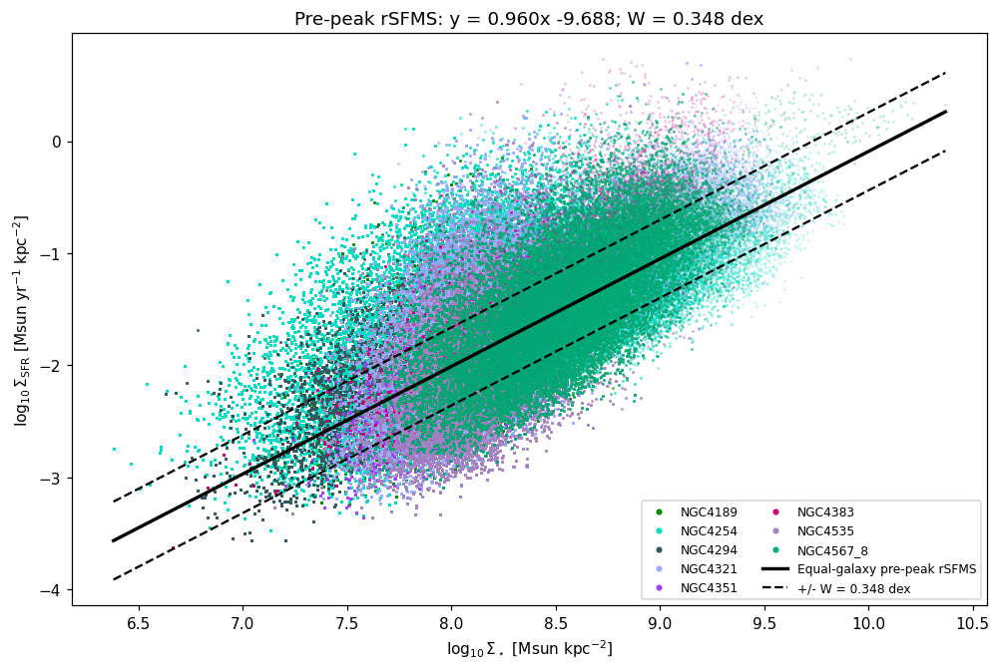

In [9]:
fig, ax = plt.subplots(figsize=(9,6), layout='constrained')
for g in pre_ids:
    f = samples[g]
    ax.scatter(f.x, f.y, color=galaxy_colors[g], s=1, alpha=.16, rasterized=True)
    # Opaque legend handles, independent of scatter transparency.
    ax.plot([], [], '.', color=galaxy_colors[g], label=g)
line_x = np.linspace(pre.x.min(), pre.x.max(), 300)
ax.plot(line_x, rsfms(line_x), color='black', lw=2.2, label='Equal-galaxy pre-peak rSFMS')
ax.plot(line_x, rsfms(line_x)+width_dex, color='black', ls='--', lw=1.5,
    label=f'+/- W = {width_dex:.3f} dex')
ax.plot(line_x, rsfms(line_x)-width_dex, color='black', ls='--', lw=1.5)
ax.set(xlabel=r'$\log_{10}\Sigma_\star$ [Msun kpc$^{-2}$]',
    ylabel=r'$\log_{10}\Sigma_{\rm SFR}$ [Msun yr$^{-1}$ kpc$^{-2}$]',
    title=f'Pre-peak rSFMS: y = {slope:.3f}x {intercept:+.3f}; W = {width_dex:.3f} dex')
ax.legend(fontsize=8, ncol=2)
plt.show()

OVERLAY_CHECKS_OK: 24 galaxies; all counts retained; common bins/colour scale


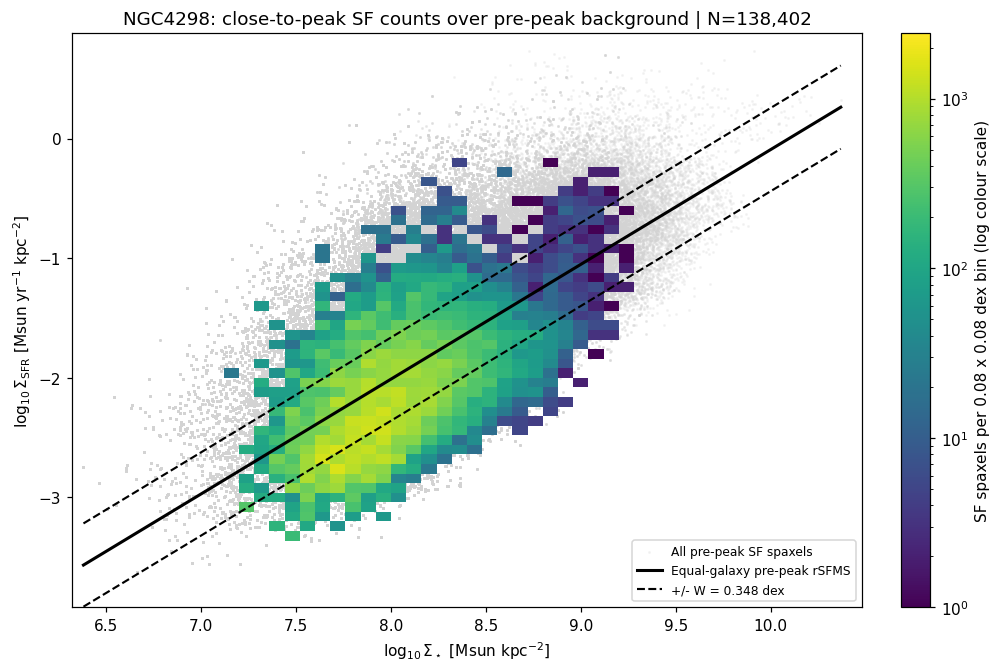

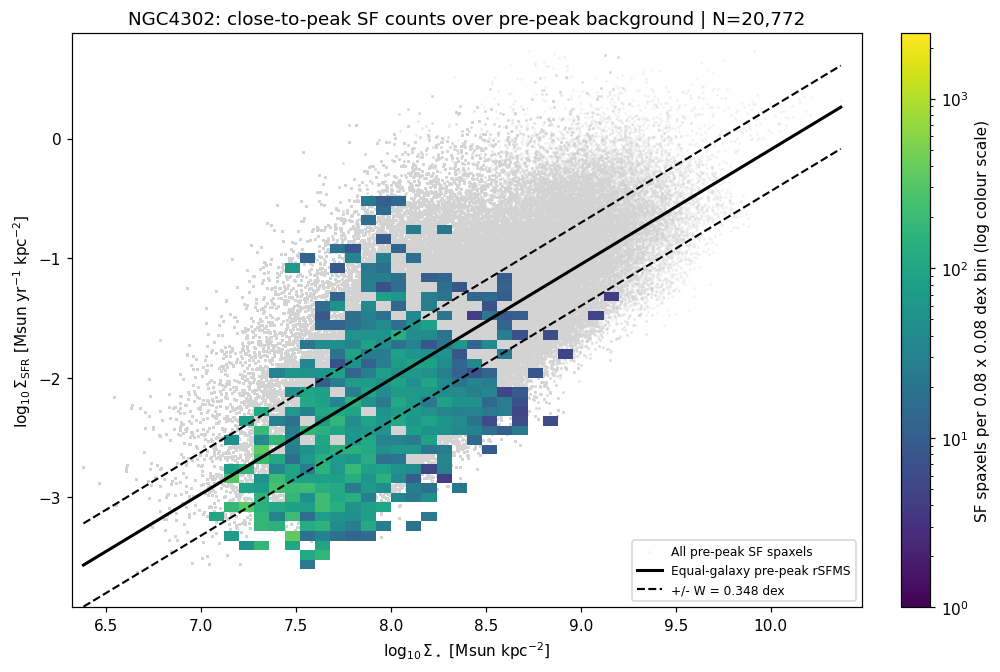

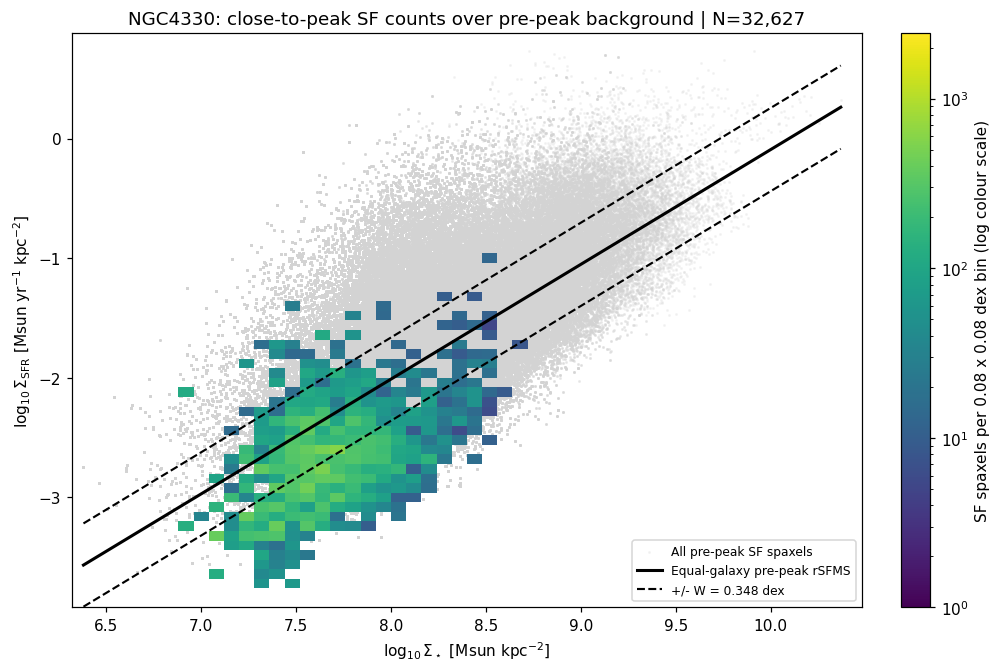

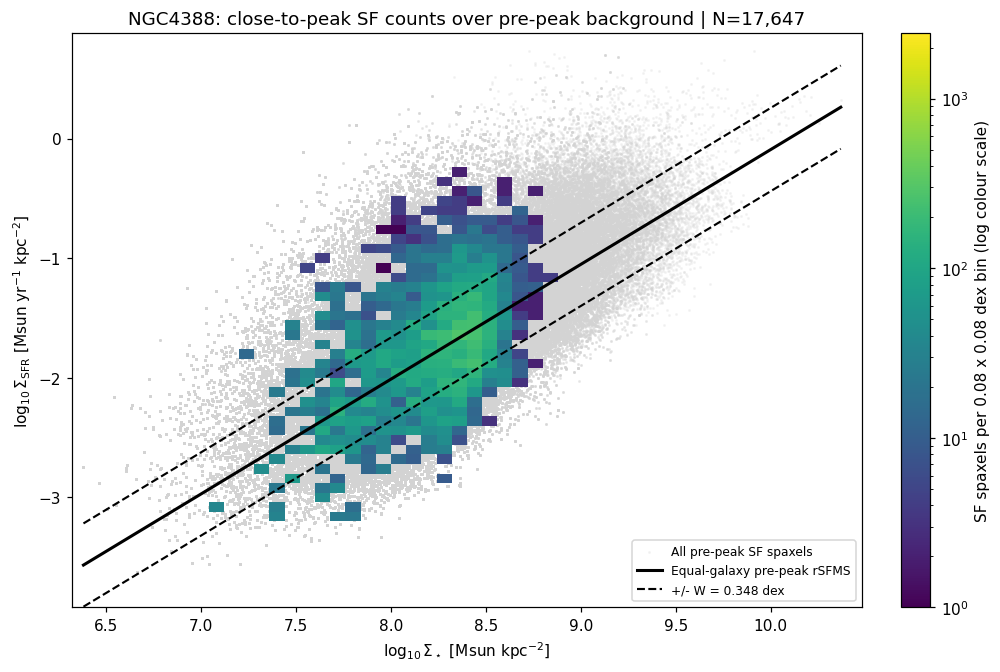

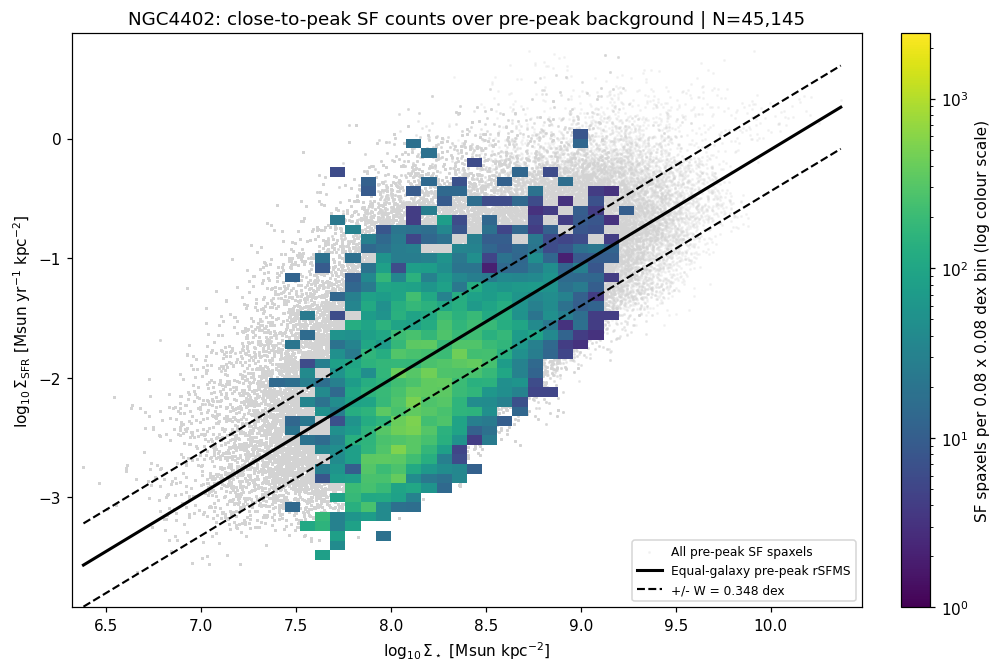

...

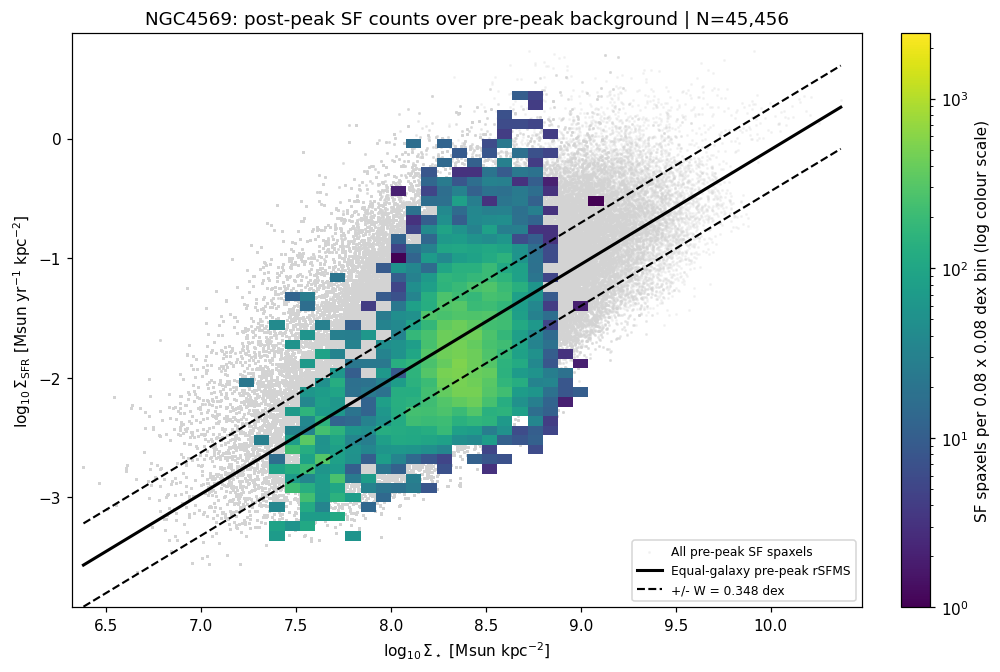

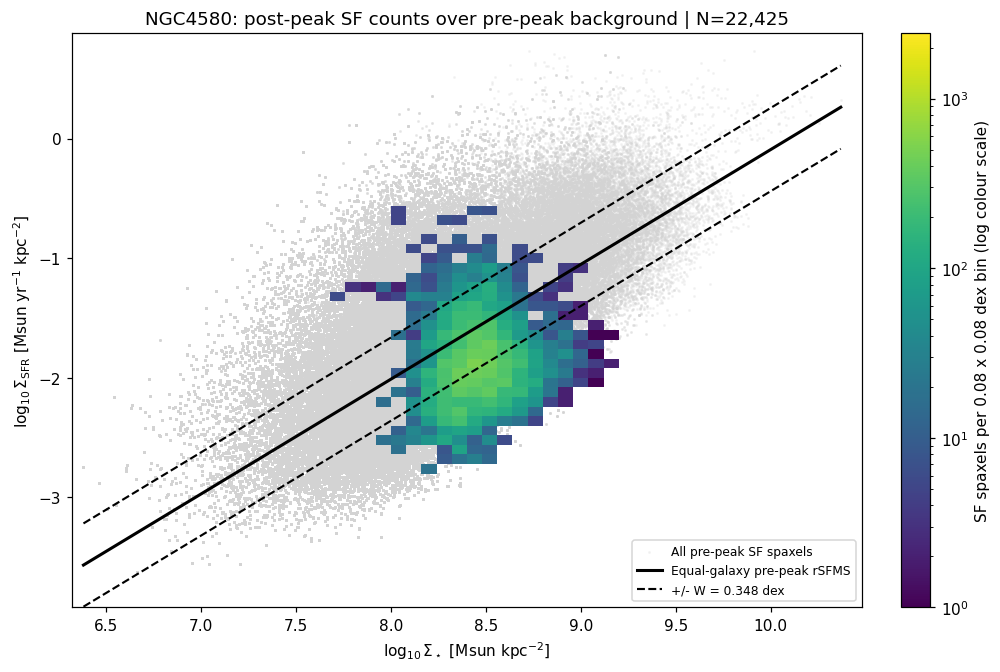

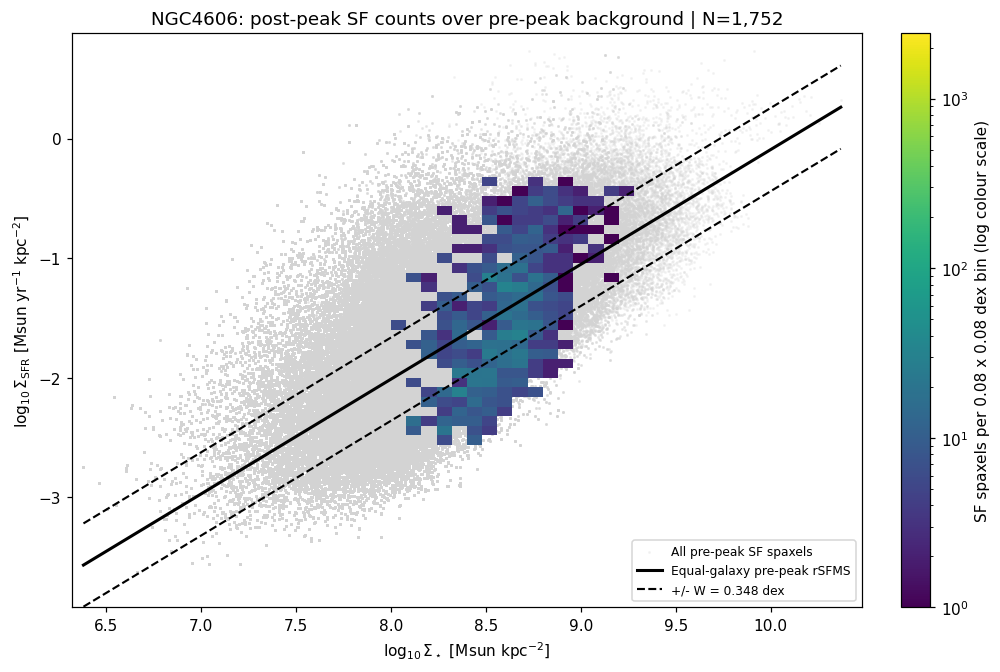

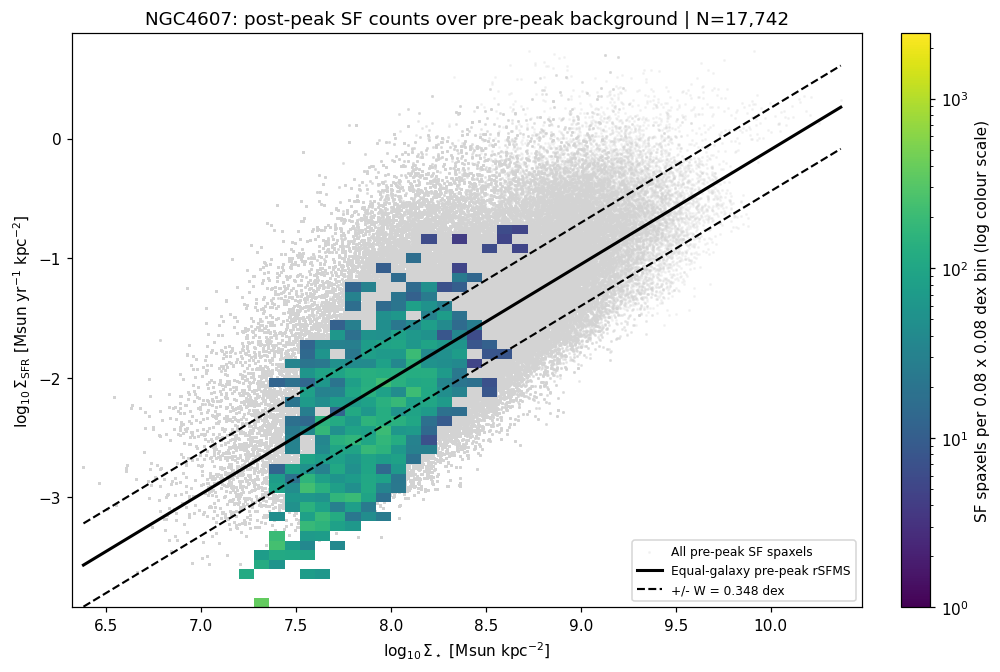

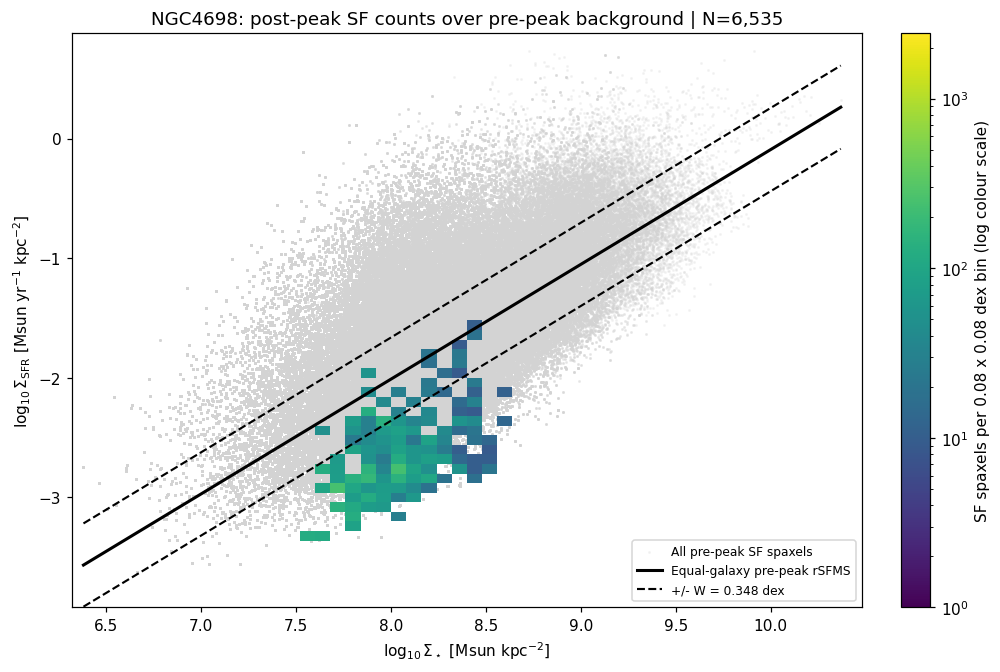

In [10]:
# One rSFMS density overlay per close-to-peak or post-peak galaxy (full SF footprint).
# All pre-peak SF spaxels remain light-gray background dots.
# Identical 0.08-dex bins and a common logarithmic colour scale show raw counts.
# No radial or directional exclusions apply.
from matplotlib.colors import LogNorm
overlay_bin_width_dex = 0.08
overlay_x_min = min(pre.x.min(), min(samples[g].x.min() for g in comparison_ids if len(samples[g])))
overlay_x_max = max(pre.x.max(), max(samples[g].x.max() for g in comparison_ids if len(samples[g])))
overlay_y_min = min(pre.y.min(), min(samples[g].y.min() for g in comparison_ids if len(samples[g])))
overlay_y_max = max(pre.y.max(), max(samples[g].y.max() for g in comparison_ids if len(samples[g])))
overlay_x_edges = np.arange(np.floor(overlay_x_min/overlay_bin_width_dex)*overlay_bin_width_dex,
    np.ceil(overlay_x_max/overlay_bin_width_dex)*overlay_bin_width_dex+2*overlay_bin_width_dex,
    overlay_bin_width_dex)
overlay_y_edges = np.arange(np.floor(overlay_y_min/overlay_bin_width_dex)*overlay_bin_width_dex,
    np.ceil(overlay_y_max/overlay_bin_width_dex)*overlay_bin_width_dex+2*overlay_bin_width_dex,
    overlay_bin_width_dex)
overlay_counts = {}
for g in comparison_ids:
    overlay_counts[g], _, _ = np.histogram2d(samples[g].x, samples[g].y,
        bins=(overlay_x_edges,overlay_y_edges))
    assert int(overlay_counts[g].sum()) == len(samples[g]), f'{g}: lost histogram spaxels'
overlay_norm = LogNorm(vmin=1, vmax=max(2, max(h.max() for h in overlay_counts.values())))
overlay_line_x = np.linspace(pre.x.min(),pre.x.max(),300)
for g in comparison_ids:
    fig, ax = plt.subplots(figsize=(9,6),layout='constrained')
    ax.scatter(pre.x,pre.y,s=1,color='lightgray',alpha=.20,rasterized=True,
        label='All pre-peak SF spaxels',zorder=1)
    h = overlay_counts[g]
    mesh = ax.pcolormesh(overlay_x_edges,overlay_y_edges,np.ma.masked_equal(h.T,0),
        cmap='viridis',norm=overlay_norm,shading='flat',rasterized=True,zorder=2)
    ax.plot(overlay_line_x,rsfms(overlay_line_x),color='black',lw=2,
        label='Equal-galaxy pre-peak rSFMS',zorder=3)
    ax.plot(overlay_line_x,rsfms(overlay_line_x)+width_dex,color='black',ls='--',lw=1.4,
        label=f'+/- W = {width_dex:.3f} dex',zorder=3)
    ax.plot(overlay_line_x,rsfms(overlay_line_x)-width_dex,color='black',ls='--',lw=1.4,zorder=3)
    ax.set(xlim=(overlay_x_edges[0],overlay_x_edges[-1]),
        ylim=(overlay_y_edges[0],overlay_y_edges[-1]),
        xlabel=r'$\log_{10}\Sigma_\star$ [Msun kpc$^{-2}$]',
        ylabel=r'$\log_{10}\Sigma_{\rm SFR}$ [Msun yr$^{-1}$ kpc$^{-2}$]',
        title=f'{g}: {selected.set_index('GALID').loc[g, 'stage']} SF counts over pre-peak background | N={len(samples[g]):,}')
    fig.colorbar(mesh,ax=ax,label='SF spaxels per 0.08 x 0.08 dex bin (log colour scale)')
    ax.legend(fontsize=8,loc='lower right')
    plt.show()
print('OVERLAY_CHECKS_OK:',len(comparison_ids),'galaxies; all counts retained; common bins/colour scale')

## 1.2. Signed excess, spatial maps, and threshold fractions

Define E=[log10 Sigma_SFR - f(log10 Sigma_star)]/W. Positive means above the
pre-peak reference and negative means below it. E is dimensionless; E is measured in units of W, not sigma significance. Width normalization is common to every
galaxy, with no per-galaxy refit or centering.

Maps show every selected SF spaxel on celestial WCS, with the same coolwarm
scale saturated at +/-4. Fractions use strict E>t for t=1,1.5,2,2.5,3,3.5,4 and all selected SF
spaxels as the denominator, including values outside the display range.
The table flags stellar densities outside the full pre-peak x range, where
the line is extrapolated. Such spaxels are retained as requested. Within that
range, matching in x does not establish matching in other physical properties.

In [12]:
fraction_rows = []
for g in pre_ids + comparison_ids:
    f = samples[g]
    f['residual_dex'] = f.y - rsfms(f.x)
    f['excess'] = f.residual_dex / width_dex
    f['outside_reference_x'] = (f.x < pre.x.min()) | (f.x > pre.x.max())
    emap = np.full(galaxy_maps[g]['sf_mask'].shape, np.nan)
    emap[galaxy_maps[g]['sf_mask']] = f.excess.to_numpy()
    galaxy_maps[g]['excess'] = emap
    result = dict(GALID=g, stage=selected.set_index('GALID').loc[g, 'stage'], N_SF=len(f),
        mean_excess=f.excess.mean(), median_excess=f.excess.median(),
        fraction_outside_reference_x=f.outside_reference_x.mean(),
        fraction_map_saturated=(f.excess.abs() > MAP_LIMIT).mean())
    for threshold in EXCESS_THRESHOLDS:
        n = int(f.excess.gt(threshold).sum())
        result[f'N_excess_gt{threshold}'] = n
        result[f'fraction_excess_gt{threshold}'] = n/len(f) if len(f) else np.nan
    fraction_rows.append(result)
fractions = pd.DataFrame(fraction_rows)
reference_fractions = fractions.loc[fractions.GALID.isin(pre_ids)]
summary_row = dict(GALID='Pre-peak equal-product mean', stage='pre-peak')
for t in EXCESS_THRESHOLDS:
    summary_row[f'fraction_excess_gt{t}'] = reference_fractions[f'fraction_excess_gt{t}'].mean()
fraction_display = pd.concat([reference_fractions,pd.DataFrame([summary_row]),fractions.loc[fractions.GALID.isin(comparison_ids)]],ignore_index=True)
print('Reference: mean of per-product fractions; counts undefined. SF spaxels are not independent regions.')
display(fraction_display)
print(fraction_display[['GALID','stage','N_SF']+[f'fraction_excess_gt{t}' for t in EXCESS_THRESHOLDS]].to_string(index=False, float_format=lambda v: f'{v:.4f}'))

Reference: mean of per-product fractions; counts undefined. SF spaxels are not independent regions.
                      GALID         stage        N_SF  fraction_excess_gt1  fraction_excess_gt1.5  fraction_excess_gt2  fraction_excess_gt2.5  fraction_excess_gt3  fraction_excess_gt3.5  fraction_excess_gt4
                    NGC4189      pre-peak  96364.0000               0.1842                 0.0968               0.0530                 0.0289               0.0163                 0.0085               0.0057
                    NGC4254      pre-peak 661963.0000               0.3978                 0.2856               0.1825                 0.1103               0.0657                 0.0309               0.0143
                    NGC4294      pre-peak  68833.0000               0.2386                 0.1396               0.0735                 0.0389               0.0112                 0.0039               0.0008
                    NGC4321      pre-peak 454131.0000               0.19

,GALID,stage,N_SF,mean_excess,median_excess,fraction_outside_reference_x,fraction_map_saturated,N_excess_gt1,fraction_excess_gt1,N_excess_gt1.5,fraction_excess_gt1.5,N_excess_gt2,fraction_excess_gt2,N_excess_gt2.5,fraction_excess_gt2.5,N_excess_gt3,fraction_excess_gt3,N_excess_gt3.5,fraction_excess_gt3.5,N_excess_gt4,fraction_excess_gt4
0,NGC4189,pre-peak,96364.0,-0.033944,-0.163338,0.000000,0.005666,17750.0,0.184197,9326.0,0.096779,5104.0,0.052966,2783.0,0.028880,1571.0,0.016303,820.0,0.008509,546.0,0.005666
1,NGC4254,pre-peak,661963.0,0.734922,0.628745,0.000000,0.014341,263299.0,0.397755,189032.0,0.285563,120793.0,0.182477,73020.0,0.110308,43475.0,0.065676,20482.0,0.030941,9493.0,0.014341
2,NGC4294,pre-peak,68833.0,0.284219,0.177335,0.000000,0.000799,16422.0,0.238577,9612.0,0.139642,5057.0,0.073468,2681.0,0.038949,774.0,0.011245,269.0,0.003908,55.0,0.000799
3,NGC4321,pre-peak,454131.0,-0.068947,-0.241484,0.000000,0.004915,89256.0,0.196542,55437.0,0.122073,32924.0,0.072499,18839.0,0.041484,10228.0,0.022522,4826.0,0.010627,2232.0,0.004915
4,NGC4351,pre-peak,30711.0,-0.603727,-0.682048,0.000000,0.000000,2462.0,0.080167,828.0,0.026961,194.0,0.006317,102.0,0.003321,3.0,0.000098,0.0,0.000000,0.0,0.000000
5,NGC4383,pre-peak,25212.0,0.348967,0.176128,0.000000,0.003768,5199.0,0.206211,3208.0,0.127241,1900.0,0.075361,1034.0,0.041012,541.0,0.021458,222.0,0.008805,95.0,0.003768
6,NGC4535,pre-peak,187113.0,-0.562502,-0.744919,0.000000,0.003094,26477.0,0.141503,17270.0,0.092297,9850.0,0.052642,5467.0,0.029218,2839.0,0.015173,1372.0,0.007332,579.0,0.003094
7,NGC4567_8,pre-peak,222533.0,-0.098988,-0.184157,0.000000,0.001407,37340.0,0.167795,19615.0,0.088144,9618.0,0.043221,4437.0,0.019939,1989.0,0.008938,910.0,0.004089,313.0,0.001407
8,Pre-peak equal-product mean,pre-peak,NaN,NaN,NaN,NaN,NaN,NaN,0.201594,NaN,0.122338,NaN,0.069869,NaN,0.039139,NaN,0.020176,NaN,0.009277,NaN,0.004249
9,NGC4298,close-to-peak,138402.0,-0.428227,-0.578310,0.000000,0.000246,15547.0,0.112332,8572.0,0.061936,3423.0,0.024732,1353.0,0.009776,610.0,0.004407,134.0,0.000968,34.0,0.000246


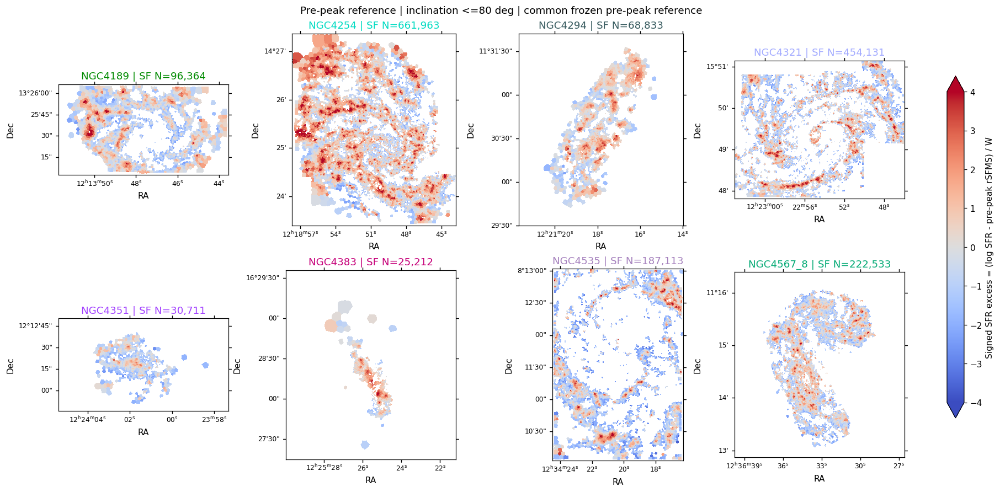

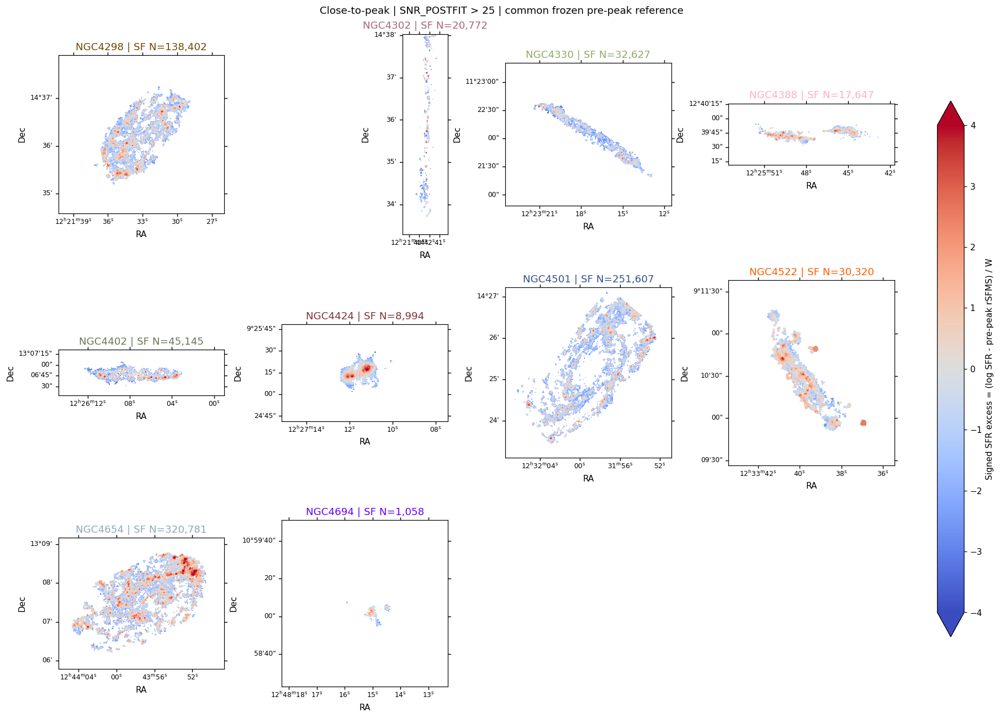

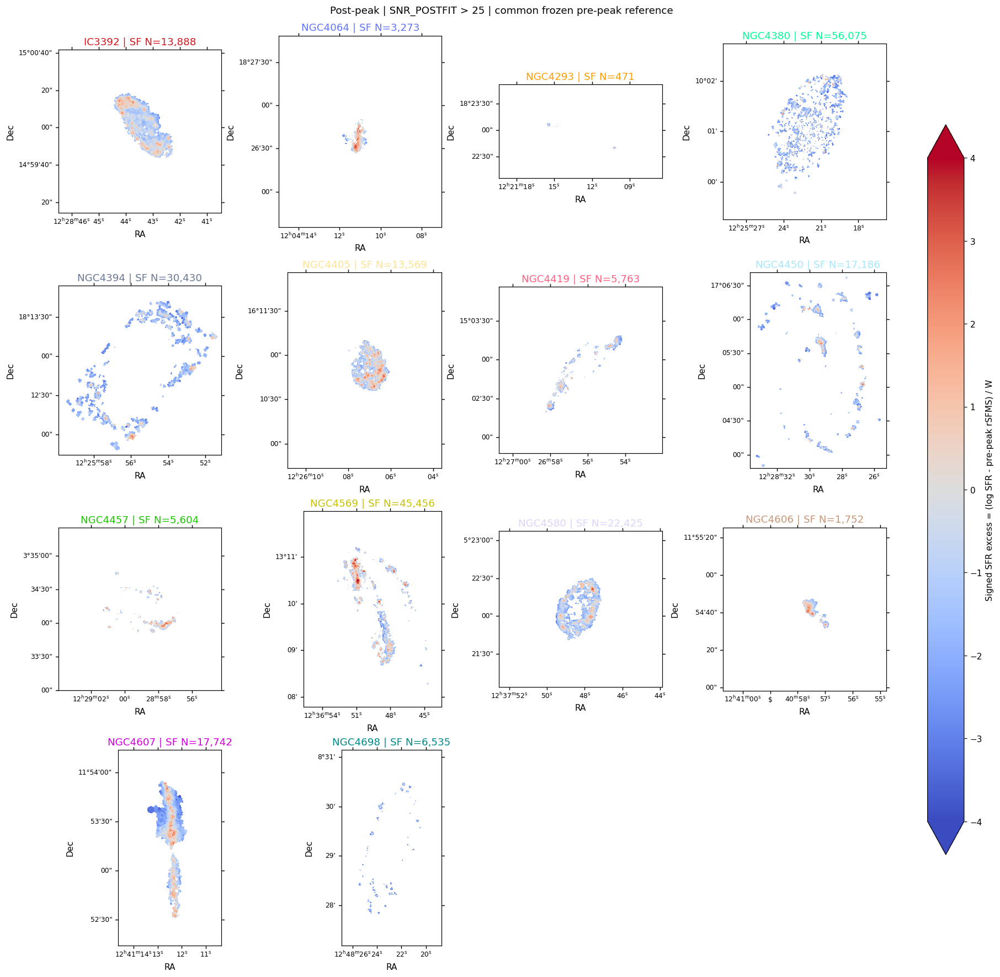

In [13]:
def plot_excess_maps(ids, stage_label):
    ncol = 3 if len(ids) <= 6 else 4
    nrow = int(np.ceil(len(ids)/ncol))
    fig = plt.figure(figsize=(4.1*ncol, 4.0*nrow), layout='constrained')
    axes = []
    for j, g in enumerate(ids):
        maps = galaxy_maps[g]
        ax = fig.add_subplot(nrow,ncol,j+1,projection=WCS(maps['header']).celestial)
        axes.append(ax)
        im = ax.imshow(maps['excess'],origin='lower',cmap='coolwarm',
            vmin=-MAP_LIMIT,vmax=MAP_LIMIT,interpolation='nearest')
        ax.set_title(f'{g} | SF N={len(samples[g]):,}', color=galaxy_colors[g])
        ax.coords[0].set_axislabel('RA')
        ax.coords[1].set_axislabel('Dec')
        ax.coords[0].set_ticklabel(size=8)
        ax.coords[1].set_ticklabel(size=8)
    fig.colorbar(im, ax=axes, shrink=.8, extend='both',
        label='Signed SFR excess = (log SFR - pre-peak rSFMS) / W')
    fig.suptitle(stage_label + ' | common frozen pre-peak reference')
    plt.show()
plot_excess_maps(pre_ids, 'Pre-peak reference | inclination <=80 deg')
plot_excess_maps(close_ids, 'Close-to-peak | SNR_POSTFIT > 25')
plot_excess_maps(post_ids, 'Post-peak | SNR_POSTFIT > 25')


CONTEXT_CHECKS_OK: 24 comparison galaxies


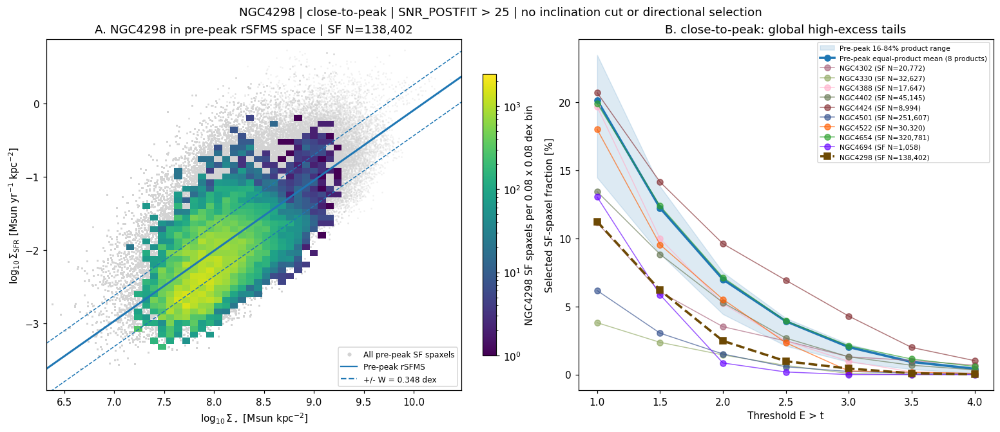

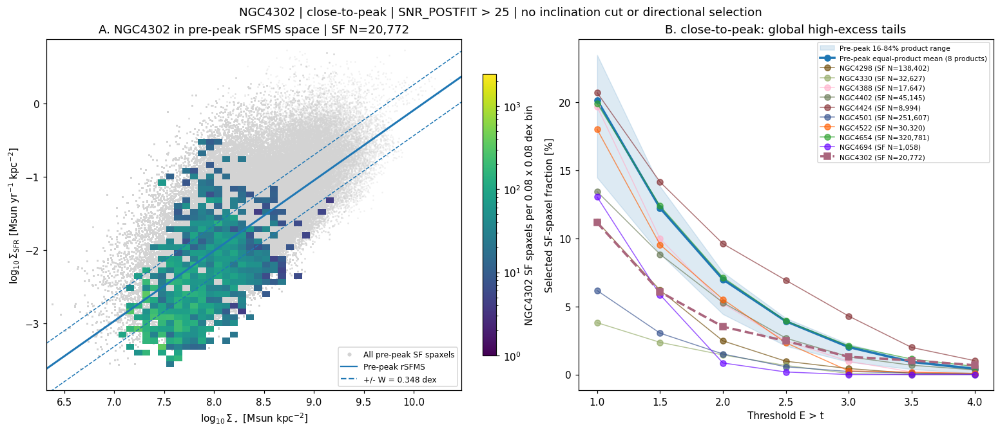

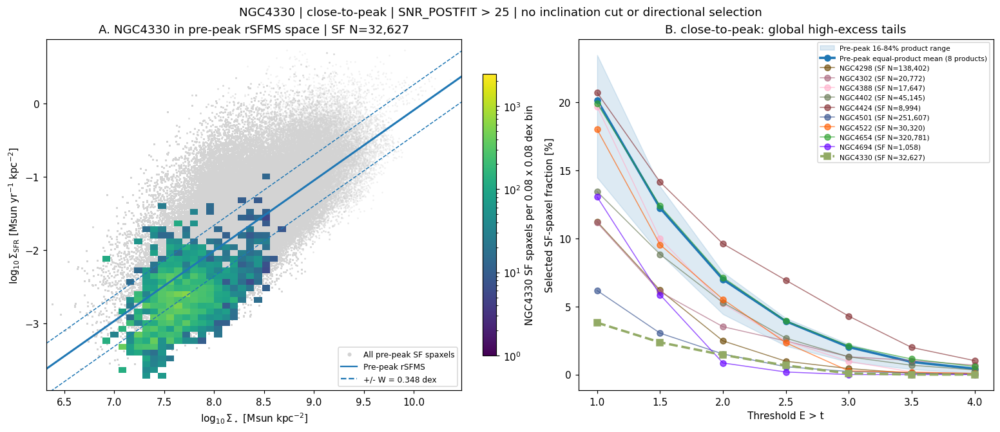

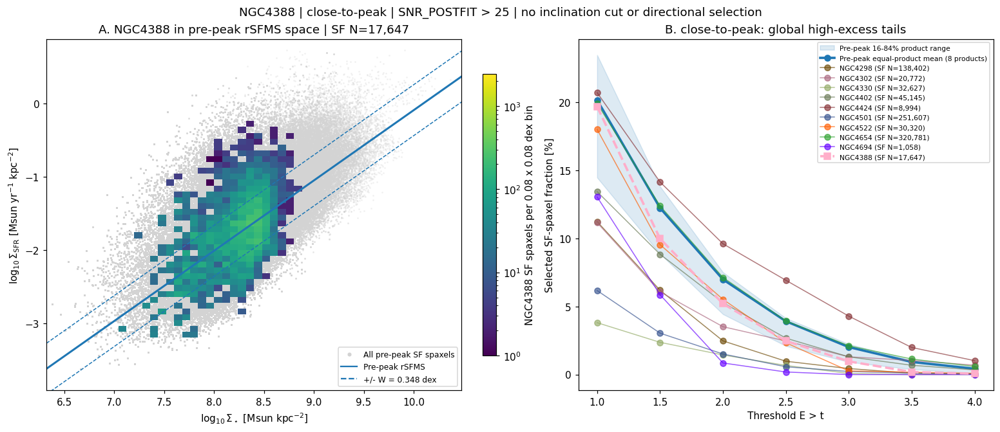

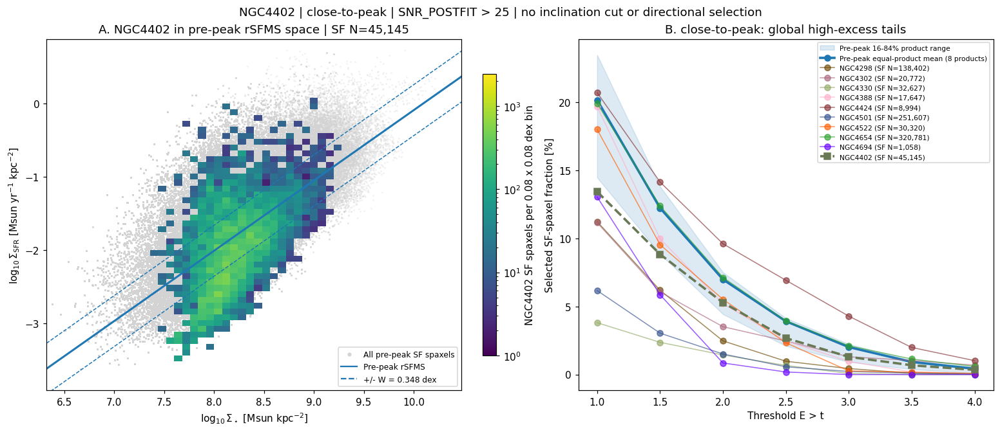

...

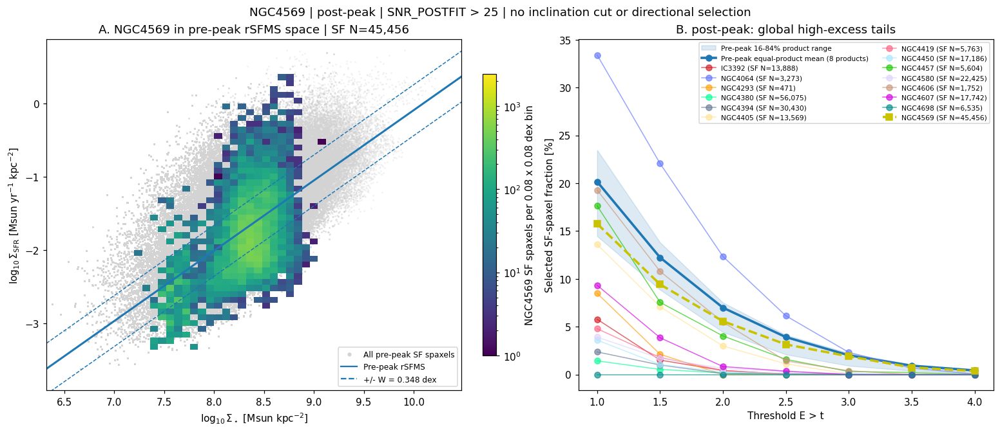

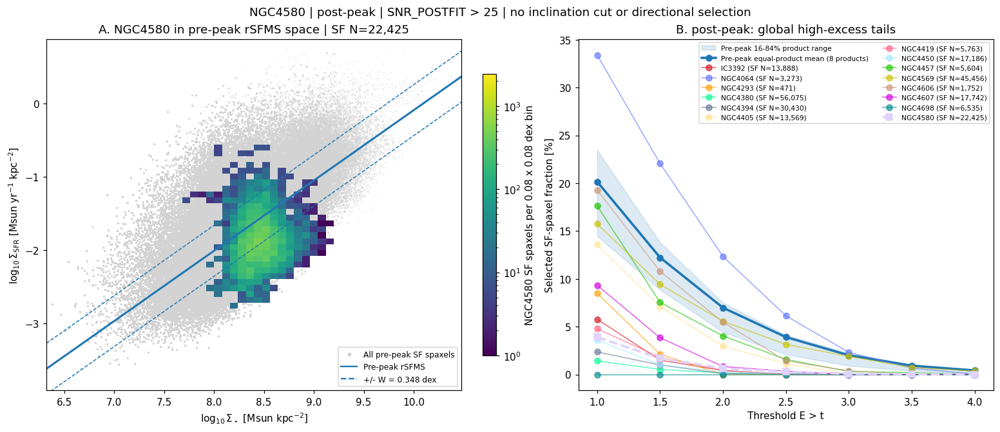

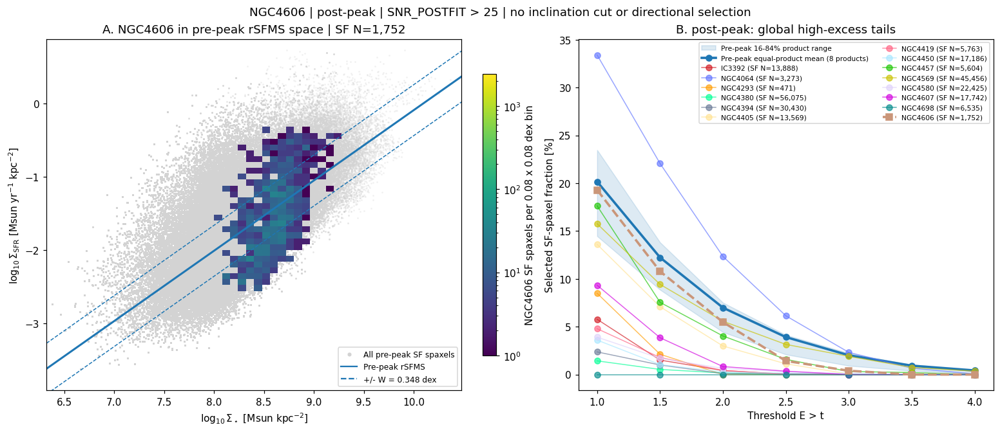

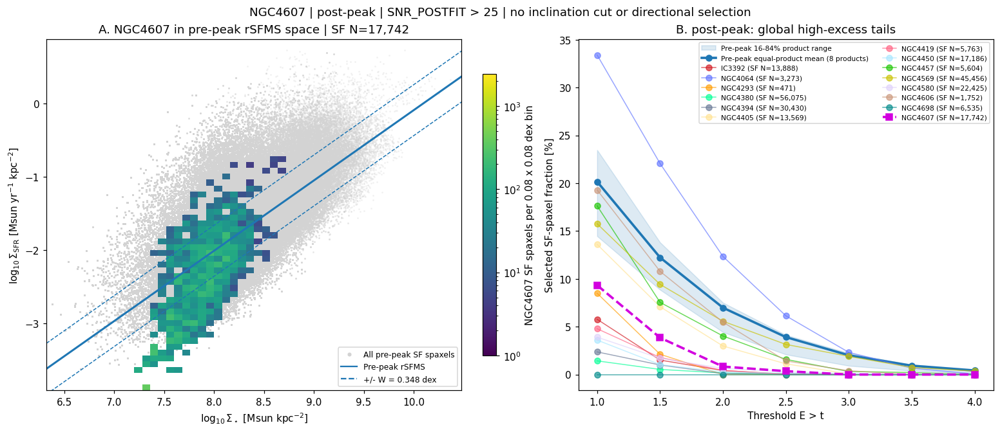

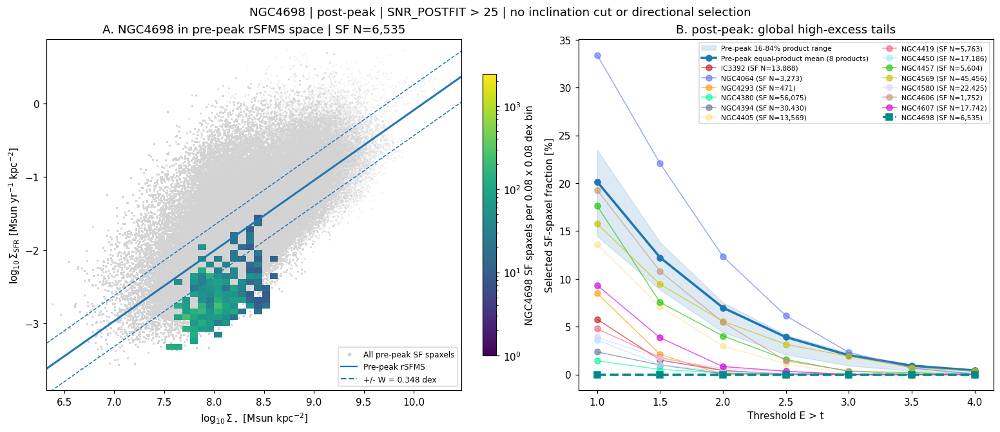

In [14]:
# Adapted source cell 34: global context for every comparison galaxy.
from matplotlib.colors import LogNorm
from matplotlib.lines import Line2D

paper_colours = {'pre_mean': '#1f77b4', 'NGC4654': '#2ca02c'}
paper_thresholds = np.asarray(EXCESS_THRESHOLDS)
paper_x_edges, paper_y_edges = overlay_x_edges, overlay_y_edges
paper_pre_fractions = fractions.loc[fractions.GALID.isin(pre_ids),
    [f'fraction_excess_gt{t}' for t in EXCESS_THRESHOLDS]].to_numpy()
paper_pre_mean = paper_pre_fractions.mean(axis=0)
paper_pre_p16, paper_pre_p84 = np.quantile(paper_pre_fractions, [.16, .84], axis=0)
for g in comparison_ids:
    stage = selected.set_index('GALID').loc[g, 'stage']
    stage_ids = close_ids if stage == 'close-to-peak' else post_ids
    target = samples[g]
    paper_fig1, axes = plt.subplots(1, 2, figsize=(14, 6), layout='constrained')
    ax = axes[0]
    ax.scatter(pre.x, pre.y, s=1, color='lightgray', alpha=.20, rasterized=True, zorder=1)
    mesh = ax.pcolormesh(paper_x_edges, paper_y_edges,
        np.ma.masked_equal(overlay_counts[g].T, 0), cmap='viridis', norm=overlay_norm,
        shading='flat', rasterized=True, zorder=2)
    paper_fig1.colorbar(mesh, ax=ax, shrink=.8,
        label=f'{g} SF spaxels per 0.08 x 0.08 dex bin')
    xx = np.linspace(paper_x_edges[0], paper_x_edges[-1], 300)
    ax.plot(xx, rsfms(xx), color=paper_colours['pre_mean'], lw=2)
    for sign in [-1, 1]:
        ax.plot(xx, rsfms(xx) + sign*width_dex, color=paper_colours['pre_mean'], ls='--', lw=1)
    ax.set(xlim=(paper_x_edges[0], paper_x_edges[-1]), ylim=(paper_y_edges[0], paper_y_edges[-1]),
        xlabel=r'$\log_{10}\Sigma_\star$ [Msun kpc$^{-2}$]',
        ylabel=r'$\log_{10}\Sigma_{\rm SFR}$ [Msun yr$^{-1}$ kpc$^{-2}$]',
        title=f'A. {g} in pre-peak rSFMS space | SF N={len(target):,}')
    ax.legend(handles=[Line2D([], [], color='lightgray', marker='.', ls='', label='All pre-peak SF spaxels'),
        Line2D([], [], color=paper_colours['pre_mean'], label='Pre-peak rSFMS'),
        Line2D([], [], color=paper_colours['pre_mean'], ls='--', label=f'+/- W = {width_dex:.3f} dex')],
        fontsize=8, loc='lower right')
    ax = axes[1]
    ax.fill_between(paper_thresholds, 100*paper_pre_p16, 100*paper_pre_p84,
        color=paper_colours['pre_mean'], alpha=.15, label='Pre-peak 16-84% product range')
    ax.plot(paper_thresholds, 100*paper_pre_mean, 'o-', color=paper_colours['pre_mean'], lw=2.4,
        label=f'Pre-peak equal-product mean ({len(pre_ids)} products)')
    # Draw the focal galaxy last so its curve remains visible.
    for other in [h for h in stage_ids if h != g] + [g]:
        row = fractions.loc[fractions.GALID.eq(other)].iloc[0]
        color = paper_colours.get(other, galaxy_colors[other])
        ax.plot(paper_thresholds,
            100*np.array([row[f'fraction_excess_gt{t}'] for t in EXCESS_THRESHOLDS]),
            's--' if other == g else 'o-', color=color,
            lw=2.4 if other == g else 1.0, alpha=1 if other == g else .65,
            label=f'{other} (SF N={int(row.N_SF):,})')
    ax.set(xticks=paper_thresholds, xlabel='Threshold E > t',
        ylabel='Selected SF-spaxel fraction [%]', title=f'B. {stage}: global high-excess tails')
    ax.legend(fontsize=7, ncol=2 if len(stage_ids) > 10 else 1)
    paper_fig1.suptitle(f'{g} | {stage} | SNR_POSTFIT > 25 | no inclination cut or directional selection')
    plt.show()
print('CONTEXT_CHECKS_OK:', len(comparison_ids), 'comparison galaxies')
